<a href="https://colab.research.google.com/github/yashaswinigowdaksys/projects/blob/main/Mobilephone_sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#linear regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
df=pd.read_csv("/content/top 120 best-selling mobile phones.csv")

In [ ]:
df

,Rank,Manufacturer,Model,Form Factor,Smartphone?,Year,Units Sold (million )
0,1,Nokia,1100,Bar,False,2003,250.0
1,2,Nokia,1110,Bar,False,2005,247.5
2,3,Apple,iPhone 6 & 6 Plus,Touchscreen,True,2014,222.4
3,4,Nokia,105 Series,Bar,False,2013,200.0
4,5,Apple,iPhone 6S & 6S Plus,Touchscreen,True,2015,174.1
...,...,...,...,...,...,...,...
115,116,Samsung,Samsung Galaxy A55,Touchscreen,True,2024,2.7
116,117,Samsung,Samsung Galaxy S24,Touchscreen,True,2024,2.4
117,118,Samsung,Samsung Galaxy A15 4G,Touchscreen,True,2023,2.2
118,119,Google,Pixel & Pixel XL,Touchscreen,True,2016,2.1


In [ ]:
df.shape

(120, 7)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Rank                   120 non-null    int64  
 1   Manufacturer           120 non-null    object 
 2   Model                  120 non-null    object 
 3   Form Factor            120 non-null    object 
 4   Smartphone?            120 non-null    bool   
 5   Year                   120 non-null    int64  
 6   Units Sold (million )  120 non-null    float64
dtypes: bool(1), float64(1), int64(2), object(3)
memory usage: 5.9+ KB


In [ ]:
df=df.rename(columns={'Smartphone?' :'smartphone'})

In [ ]:
df.isnull().sum()

,0
Rank,0
Manufacturer,0
Model,0
Form Factor,0
smartphone,0
Year,0
Units Sold (million ),0


In [ ]:
df.duplicated().sum().sum()

np.int64(0)

In [ ]:
df.describe()

,Rank,Year,Units Sold (million )
count,120.000000,120.000000,120.000000
mean,60.500000,2012.758333,48.050000
std,34.785054,6.590030,58.044835
min,1.000000,1996.000000,2.000000
25%,30.750000,2007.000000,10.000000
50%,60.500000,2013.000000,22.050000
75%,90.250000,2019.000000,60.000000
max,120.000000,2024.000000,250.000000


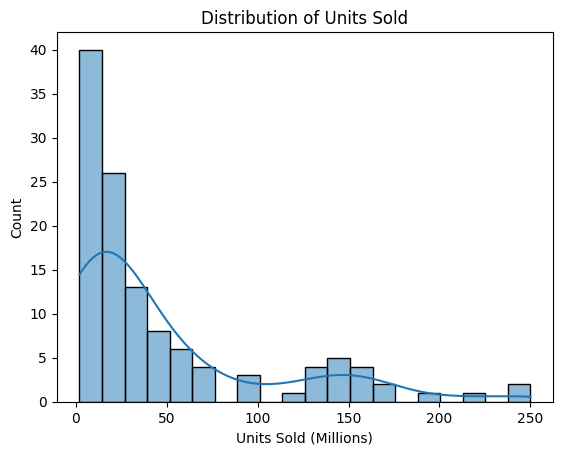

In [ ]:
#Visualize the distribution of units sold using a histogram.
sns.histplot(df["Units Sold (million )"], bins = 20, kde = True)
plt.title('Distribution of Units Sold')
plt.xlabel('Units Sold (Millions)')
plt.ylabel('Count')
plt.show()

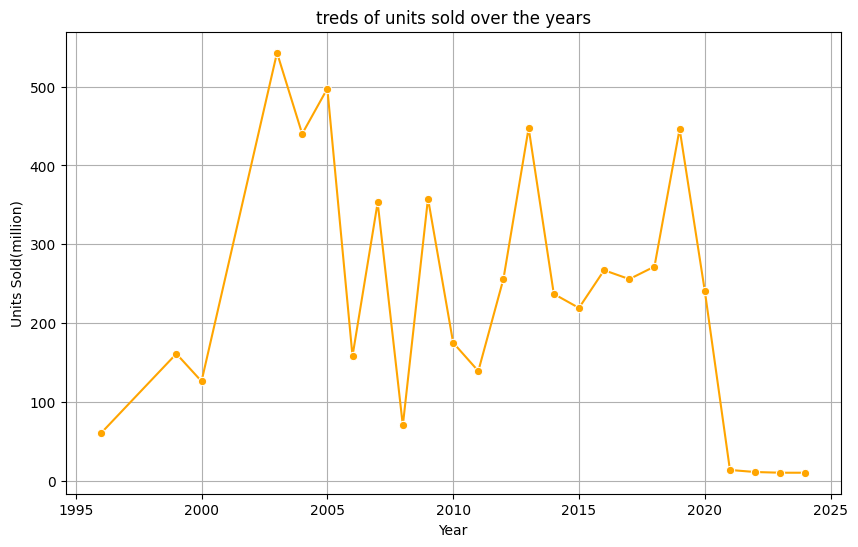

In [ ]:
#Plot the trend of units sold over the years using a line chart.

trend_df = df.groupby('Year')['Units Sold (million )'].sum().reset_index()
plt.figure(figsize=(10,6))
sns.lineplot(data=trend_df, x='Year', y='Units Sold (million )',marker='o',color='orange')
plt.title("treds of units sold over the years")
plt.xlabel("Year")
plt.ylabel("Units Sold(million)")
plt.grid(True)
plt.show()



In [ ]:
from scipy import stats

In [ ]:
#Perform a t-test to determine if there is a significant difference in the units sold between smartphones and non-smartphones.

smartphones = df[df['smartphone'] == True]['Units Sold (million )']
non_smartphones = df[df['smartphone'] == False]['Units Sold (million )']
t_stat, p_val = stats.ttest_ind(smartphones, non_smartphones)#, equal_var=False)


print("t_statistics",t_stat)
print("p_value",p_val)



t_statistics -3.3881329319072755
p_value 0.0009570509480181121


In [ ]:
if p_val <0.05:
  print("there is a significant difference in the units sold between smartphones and non-smartphones.")
else:
  print("there is NO significant difference in the units sold between smartphones and non-smartphones.")

there is a significant difference in the units sold between smartphones and non-smartphones.


In [ ]:
df.columns

Index(['Rank', 'Manufacturer', 'Model', 'Form Factor', 'smartphone', 'Year',
       'Units Sold (million )'],
      dtype='object')

In [ ]:
#Calculate the correlation matrix and visualize it using a heatmap.
numeric_cols=df[['Rank','Year','Units Sold (million )']]

In [ ]:
corr_matrix= numeric_cols.corr()

In [ ]:
corr_matrix

,Rank,Year,Units Sold (million )
Rank,1.000000,0.380899,-0.83691
Year,0.380899,1.000000,-0.31453
Units Sold (million ),-0.836910,-0.314530,1.00000


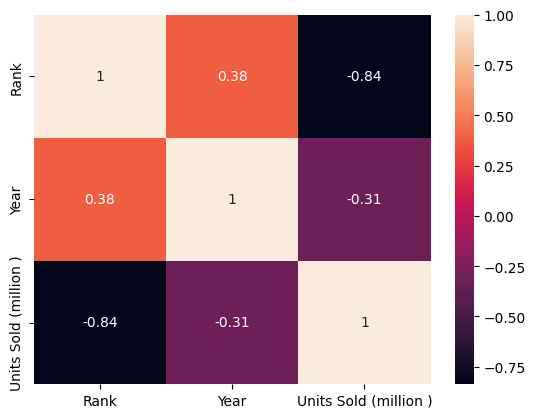

In [ ]:
sns.heatmap(corr_matrix,annot=True)
plt.show()

##3.	Data Manipulation with Pandas:

In [ ]:
#Group the data by manufacturer and calculate the total units sold for each.
manufacturer_units_sold= df.groupby('Manufacturer')['Units Sold (million )'].sum()
manufacturer_units_sold

,Units Sold (million )
Manufacturer,
Apple,1669.3
Google,2.1
HTC,16.0
Huawei,113.8
LG,92.0
LeTV,3.0
Motorola,323.0
Nokia,2374.5
Oppo,16.7


In [ ]:
# Identify the top 5 manufacturers with the highest total units sold
top_manufacturers = manufacturer_units_sold.nlargest(5)
top_manufacturers

,Units Sold (million )
Manufacturer,
Nokia,2374.5
Apple,1669.3
Samsung,994.5
Motorola,323.0
Huawei,113.8


In [ ]:
#Create a pivot table showing the total units sold per year for each manufacturer

sales_pivot = df.pivot_table(
    values='Units Sold (million )',
    index='Year',
    columns='Manufacturer',
    aggfunc='sum',
    fill_value=0  # Fills years where a manufacturer didn't have top-selling phones with 0
)



In [ ]:
sales_pivot

Manufacturer,Apple,Google,HTC,Huawei,LG,LeTV,Motorola,Nokia,Oppo,Palm,Research in Motion (RIM),Samsung,Sony Ericsson,Xiaomi
Year,,,,,,,,,,,,,,
1996,0.0,0.0,0.0,0.0,0.0,0.0,60.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,161.0,0.0,0.0,0.0,0.0,0.0,0.0
2000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,126.0,0.0,0.0,0.0,0.0,0.0,0.0
2003,0.0,0.0,0.0,0.0,0.0,0.0,60.0,473.0,0.0,0.0,0.0,10.0,0.0,0.0
2004,0.0,0.0,0.0,0.0,0.0,0.0,130.0,295.0,0.0,0.0,0.0,0.0,15.0,0.0
2005,0.0,0.0,0.0,0.0,0.0,0.0,60.0,422.5,0.0,0.0,0.0,0.0,15.0,0.0
2006,0.0,0.0,0.0,0.0,21.0,0.0,0.0,77.0,0.0,0.0,15.0,30.0,15.0,0.0
2007,6.0,0.0,0.0,0.0,5.0,0.0,0.0,340.0,0.0,2.0,0.0,0.0,0.0,0.0
2008,0.0,0.0,0.0,0.0,40.0,0.0,0.0,30.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
df['Model']

,Model
0,1100
1,1110
2,iPhone 6 & 6 Plus
3,105 Series
4,iPhone 6S & 6S Plus
...,...
115,Samsung Galaxy A55
116,Samsung Galaxy S24
117,Samsung Galaxy A15 4G
118,Pixel & Pixel XL


In [ ]:
df['Manufacturer']

,Manufacturer
0,Nokia
1,Nokia
2,Apple
3,Nokia
4,Apple
...,...
115,Samsung
116,Samsung
117,Samsung
118,Google


##4.	Data Visualization with Matplotlib and Seaborn:

In [ ]:
#Create a bar chart showing the top 10 best-selling mobile phone models
data = {
    'Model': [
        'Nokia 1100', 'Nokia 1110', 'iPhone 6 / 6 Plus', 'Nokia 105 Series',
        'iPhone 6S / 6S Plus', 'iPhone 5s', 'Nokia 3210', 'iPhone 7 / 7 Plus',
        'iPhone 11 Series', 'iPhone XR / XS Max'
    ],
    'Manufacturer': [
        'Nokia', 'Nokia', 'Apple', 'Nokia', 'Apple',
        'Apple', 'Nokia', 'Apple', 'Apple', 'Apple'
    ],
    'Units_Sold_Millions': [250.0, 248.0, 222.0, 200.0, 174.0, 165.0, 161.0, 160.0, 159.0, 151.0]
}


In [ ]:
df_top10=pd.DataFrame(data)
df_top10

,Model,Manufacturer,Units_Sold_Millions
0,Nokia 1100,Nokia,250.0
1,Nokia 1110,Nokia,248.0
2,iPhone 6 / 6 Plus,Apple,222.0
3,Nokia 105 Series,Nokia,200.0
4,iPhone 6S / 6S Plus,Apple,174.0
5,iPhone 5s,Apple,165.0
6,Nokia 3210,Nokia,161.0
7,iPhone 7 / 7 Plus,Apple,160.0
8,iPhone 11 Series,Apple,159.0
9,iPhone XR / XS Max,Apple,151.0


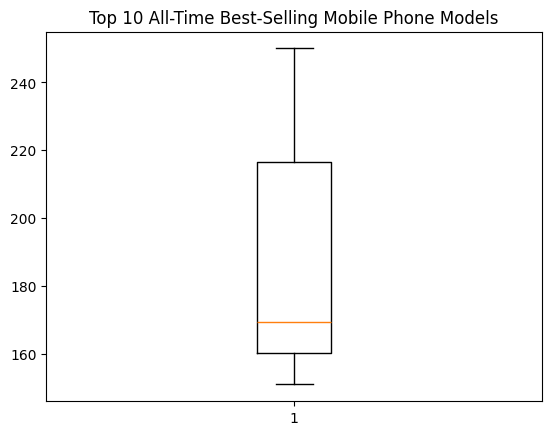

In [ ]:
plt.boxplot(df_top10['Units_Sold_Millions'])
x='Units_Sold_Millions',
y='Model',
plt.title('Top 10 All-Time Best-Selling Mobile Phone Models')
data=df_top10,
plt.show()

In [ ]:
data = {
    'Model': [
        'Nokia 1100', 'Nokia 1110', 'iPhone 6 / 6 Plus', 'Nokia 105 Series',
        'iPhone 6S / 6S Plus', 'iPhone 5s', 'Nokia 3210', 'iPhone 7 / 7 Plus',
        'iPhone 11 Series', 'iPhone XR / XS Max', 'Nokia 6600', 'Nokia 1200',
        'Nokia 5230', 'Samsung E1100', 'iPhone 12 Series', 'Nokia 2600',
        'Motorola RAZR V3', 'iPhone 8 / 8 Plus', 'Nokia 3310', 'iPhone X'
    ],
    'Units_Sold_Millions': [
        250.0, 248.0, 222.0, 200.0, 174.0, 165.0, 161.0, 160.0,
        159.0, 151.0, 150.0, 150.0, 150.0, 150.0, 148.0, 135.0,
        130.0, 125.0, 126.0, 114.0
    ],
    'Type': [
        'Non-Smartphone', 'Non-Smartphone', 'Smartphone', 'Non-Smartphone',
        'Smartphone', 'Smartphone', 'Non-Smartphone', 'Smartphone',
        'Smartphone', 'Smartphone', 'Non-Smartphone', 'Non-Smartphone',
        'Smartphone', 'Non-Smartphone', 'Smartphone', 'Non-Smartphone',
        'Non-Smartphone', 'Smartphone', 'Non-Smartphone', 'Smartphone'
    ]
}


In [ ]:
df_phones = pd.DataFrame(data)

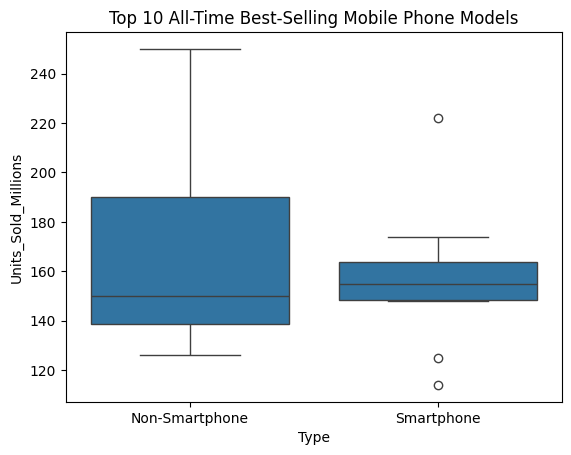

In [ ]:
sns.boxplot(
    x='Type',
    y='Units_Sold_Millions',
    data=df_phones
)
plt.title('Top 10 All-Time Best-Selling Mobile Phone Models')
plt.xlabel('Type')
plt.ylabel('Units_Sold_Millions')
plt.show()

##Machine Learning:

* Build a simple linear regression model to predict units sold based on the year.

* Evaluate the model's performance using R-squared and mean squared error.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
np.random.seed(42)
years = np.random.choice(np.arange(2010, 2026), size=144)
units_sold = 50 * (years - 2010) + 100 + np.random.normal(0, 30, size=144)

In [ ]:
df = pd.DataFrame({'Year': years, 'Units_Sold': units_sold})
df

,Year,Units_Sold
0,2016,430.929986
1,2013,277.938404
2,2022,674.823474
3,2024,790.723629
4,2020,609.937903
...,...,...
139,2018,462.627837
140,2017,455.195428
141,2010,111.559521
142,2021,623.484277


In [ ]:
#Build a simple linear regression model to predict units sold based on the year.
X = df[['Year']]
y = df['Units_Sold']


In [ ]:
# Ensure the first item has double brackets
X_train, X_test, y_train, y_test = train_test_split(df[['Year']], df['Units_Sold'], test_size=24, random_state=42)


In [ ]:
model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [ ]:
if isinstance(X_test, pd.Series):
    X_test = X_test.to_frame()

In [ ]:
y_pred = model.predict(X_test)
y_pred

array([748.38501237, 203.8770344 , 698.8842871 , 253.37775967,
       847.38646291, 599.88283656, 500.88138602, 154.37630913,
       253.37775967, 451.38066075, 748.38501237, 797.88573764,
       352.37921021, 698.8842871 , 797.88573764, 401.87993548,
       154.37630913, 748.38501237, 451.38066075, 550.38211129,
       401.87993548, 302.87848494, 847.38646291, 748.38501237])

In [ ]:
comparison_df = pd.DataFrame({
    'Actual': y_test.values.flatten(),
    'Predicted': y_pred.flatten()
})

In [ ]:
comparison_df.head()

,Actual,Predicted
0,725.525691,748.385012
1,246.939310,203.877034
2,676.502401,698.884287
3,260.393446,253.377760
4,792.436864,847.386463


In [ ]:
r2_score(y_test,y_pred)

0.9795774701880009

In [ ]:
mse=mean_squared_error(y_test,y_pred)
mse

987.1026546360969

In [ ]:
rmse = np.sqrt(mse) #mse ** 0.5
print(rmse)

31.418189868865724


In [ ]:
#